In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Simple Derivative

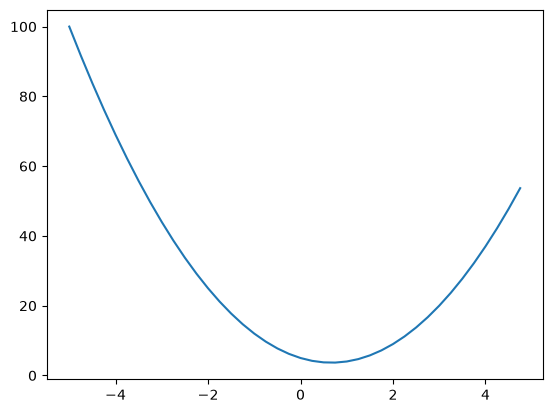

In [2]:
def f(x):
    return 3*x**2 - 4*x +5
f(3.0)
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs, ys)


In [3]:
h = 0.0000001
x = -3
(f(x+h)-f(x))/h

-21.999999688659955

# Partial Derivative

In [4]:
a = 2
b = -3
c = 10.0
d = a*b +c
print(d)

4.0


In [5]:
a = 2
b = -3
c = 10.0
d = a*b +c
print(d)

h = 0.0000001
d1 = a*b + c
a += h
d2 = a*b + c

print("d1", d1)
print("d2", d2)
print((d2-d1)/h)


4.0
d1 4.0
d2 3.9999997
-2.9999999995311555


In [6]:
def g(a,b,c):
    return a*b+c
def partial_derivative(n, h):
    if n==1:
        return (g(a+h,b,c)-g(a,b,c))/h
    if n==2:
        return (g(a,b+h,c)-g(a,b,c))/h
    if n==3:
            return (g(a,b,c+h)-g(a,b,c))/h
print(partial_derivative(1,h))
print(partial_derivative(2,h))
print(partial_derivative(3,h))

-2.9999999906493713
2.0000001033082526
0.999999993922529


# Data Structure

In [7]:
class Value: 

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data+other.data, (self, other), _op='+') 

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward

        return out
    def __radd__(self, other):
        return self + other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data*other.data, (self, other), _op='*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward

        return out
    def __rmul__(self, other):
        return self * other

    def __truediv__(self, other):
        return self * other ** -1

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self, ), f"**{other}")

        def _backward():
            self.grad += other * (self.data**(other - 1)) * out.grad
        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), "exp")

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out

    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [8]:
a = Value(2.0)
b = Value(4.0)
a-b

Value(data=-2.0)

In [9]:
# example of using the data structure
a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10.0, label = 'c')
e = a*b; e.label = 'e'
d = e+c; d.label = 'd'
f = Value(-2.0, label = 'f')
L = d * f; L.label = "L"
print(L)
print(L._prev)

Value(data=-8.0)
{Value(data=-2.0), Value(data=4.0)}


# Operation Visualization


In [10]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    # create a digraph object
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})

    nodes, edges = trace(root)
    for n in nodes:
        # for every value in the graph, create a rectangular node for it
        node_id = str(id(n))
        dot.node(name=node_id, label="{%s | data %.4f | %.4f}"%(n.label, n.data, n.grad), shape = "record")
        if n._op:
            # if this value is a result of an operation, create an operation node for it
            dot.node(name=node_id + n._op, label = n._op)
            # connect operation node to the value
            dot.edge(node_id + n._op, node_id)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


In [11]:
L.grad = 1 # dL/dL
f.grad = d.data # dL/df
d.grad = f.data # dL/dd
e.grad = 1 * d.grad # dL/de
c.grad = 1 * d.grad # dL/dc
a.grad = b.data * e.grad # dL/da
b.grad = a.data * e.grad # dL/db

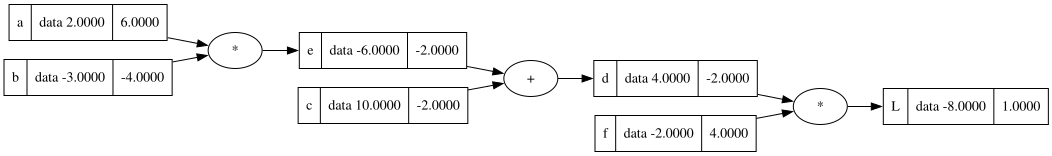

In [12]:
draw_dot(L)

# Simple Model of a neural network

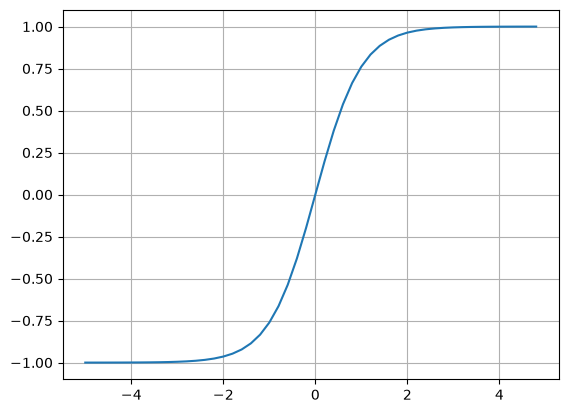

In [13]:
# plot of tanh
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid()

In [14]:
# inputs x1, x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label = "x2")
# weights w1, w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron
b = Value(6.88137, label="b")
# x1w1 + x2w2 +b
x1w1 = x1*w1; x1w1.label="x1*w1"
x2w2 = x2*w2; x2w2.label="x2*w2"
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label="x1w1 + x2w2"
n = x1w1x2w2 + b; n.label="n"
o = n.tanh(); o.label="o"
o.backward()


In [15]:
# manual back propogation
o.grad = 0 # do/do
n.grad = 1 - o.data ** 2  # do/dn
b.grad = 1  # do/db
x1w1x2w2.grad = 1 * n.grad  # do/dx1w1x2w2
x1w1.grad = 1 * x1w1x2w2.grad  # do/dx1w1
x2w2.grad = 1 * x1w1x2w2.grad  # do/dx2w2
w1.grad = x1.data * x1w1.grad  # do/dw1
x1.grad = w1.data * x1w1.grad  # do/dx1
w2.grad = x2.data * x2w2.grad  # do/dw2
x2.grad = w2.data * x2w2.grad  # do/dx2

In [16]:
# automated back propagation
o.grad = 1.0
o._backward()
n._backward()
b._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()


In [17]:
# topological sort, ensuring everything related to the final node is included 
# in a list topo in a topological order (earlier values are put first in the 
# list)
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)

o.grad = 1.0
for node in reversed(topo):
    node._backward()

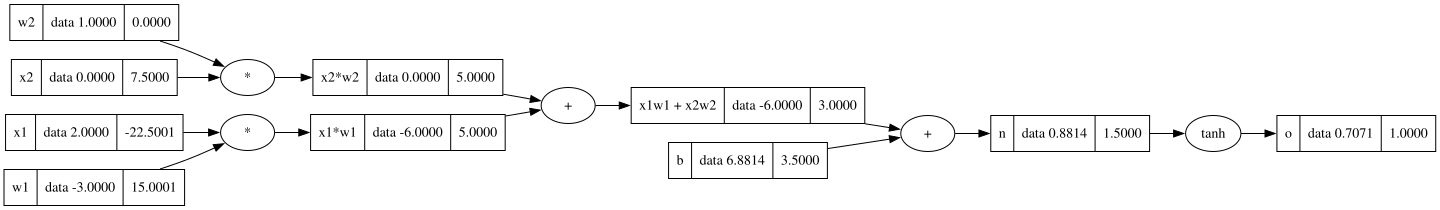

In [18]:
draw_dot(o)

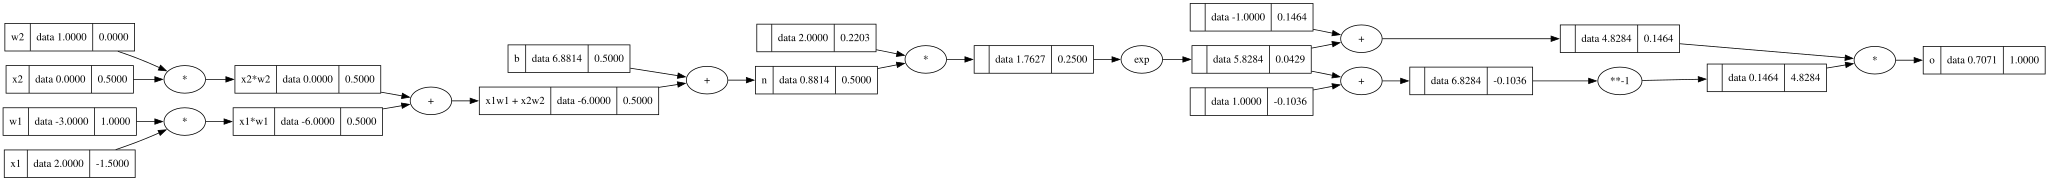

In [19]:
# inputs x1, x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label = "x2")
# weights w1, w2
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron
b = Value(6.88137, label="b")
# x1w1 + x2w2 +b
x1w1 = x1*w1; x1w1.label="x1*w1"
x2w2 = x2*w2; x2w2.label="x2*w2"
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label="x1w1 + x2w2"
n = x1w1x2w2 + b; n.label="n"
# --------
e = (2*n).exp()
o = (e-1)/(e+1)
# --------
o.label="o"
o.backward()

draw_dot(o)


### More Examples with back propogation with one variable used multiple times

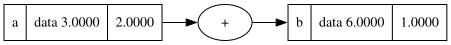

In [20]:
a = Value(3.0, label="a")
b = a + a; b.label="b"
b.backward()
draw_dot(b)

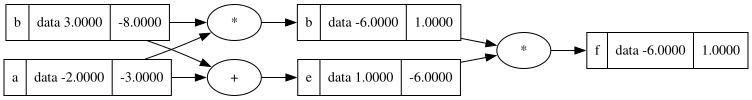

In [21]:
a = Value(-2.0, label="a")
b = Value(3.0, label="b")
d = a * b; d.label="b"
e = a + b; e.label="e"
f = d * e; f.label="f"
f.backward()

draw_dot(f)

# Implementation for Pytorch

In [22]:
import torch

In [23]:
x1 = torch.Tensor([2.0]).double()               ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()               ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()              ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()               ; w2.requires_grad = True
b = torch.Tensor([6.8813735]).double()          ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("-------")
print("x1", x1.grad.item())
print("w1", w1.grad.item())
print("x2", x2.grad.item())
print("w2", w2.grad.item())

0.7071066904050358
-------
x1 -1.5000003851533106
w1 1.0000002567688737
x2 0.5000001283844369
w2 0.0


# Implementation for Neurons built on Value

In [190]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [neuron(x) for neuron in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    
x = [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1])
n(x)
n.parameters()

[Value(data=0.19220607628649256),
 Value(data=-0.5776135271354979),
 Value(data=-0.812663611649834),
 Value(data=0.8765016218687693),
 Value(data=-0.7669875445193433),
 Value(data=0.8131162405703705),
 Value(data=-0.819608543024495),
 Value(data=0.22097682771525462),
 Value(data=-0.14298188906232379),
 Value(data=0.2627837186815878),
 Value(data=-0.248180762635982),
 Value(data=0.0016113018384324995),
 Value(data=0.46624393024661903),
 Value(data=0.19059389251288272),
 Value(data=-0.9070388899813757),
 Value(data=0.8454043012137438),
 Value(data=0.5999228954873843),
 Value(data=-0.17794609730225175),
 Value(data=-0.7621356299988757),
 Value(data=-0.8741079104883598),
 Value(data=-0.1863317923339196),
 Value(data=-0.9869776337706768),
 Value(data=0.16852406321212832),
 Value(data=0.9286125700884664),
 Value(data=-0.0969011589333253),
 Value(data=0.7181445058613656),
 Value(data=-0.4659508987298049),
 Value(data=-0.15541190700157115),
 Value(data=-0.5343815535158007),
 Value(data=0.51934

In [67]:
len(n.parameters())

41

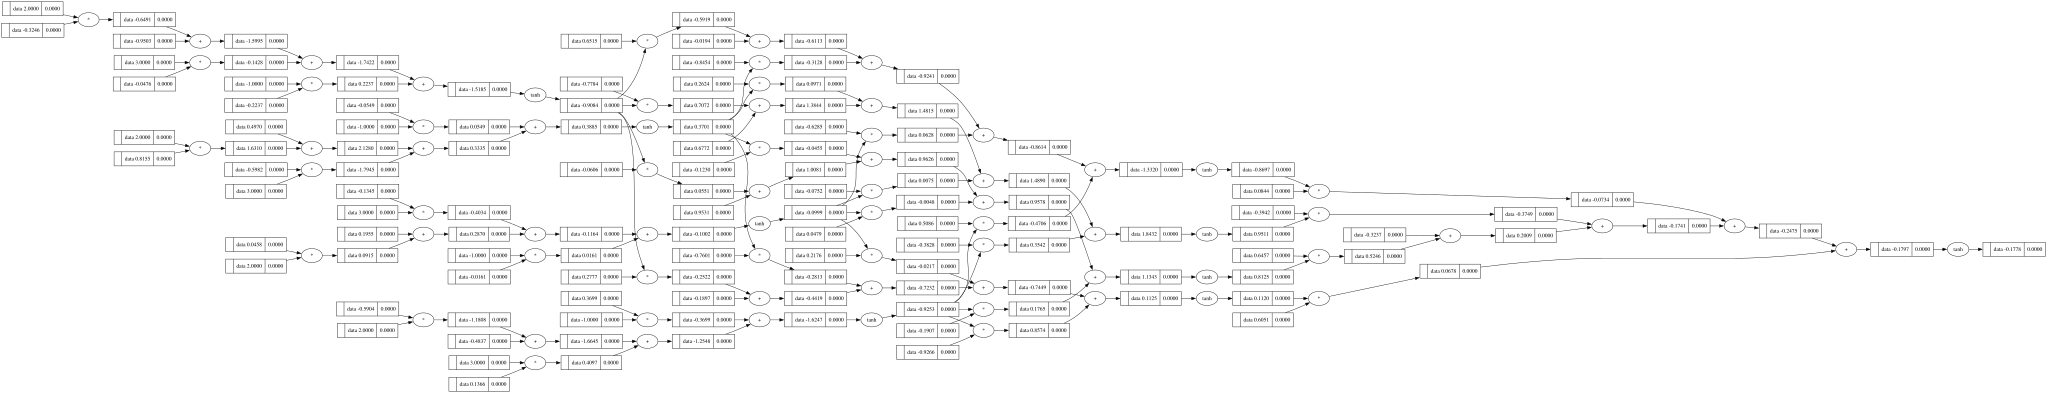

In [68]:
draw_dot(n(x))

# Loss Function

In [191]:
# inputs and expected outputs
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]
ypred = [n(x) for x in xs]
ypred

[Value(data=-0.7942764935122217),
 Value(data=0.011995389576463154),
 Value(data=-0.7760794559846634),
 Value(data=-0.707011800191232)]

In [ ]:
# ygt stands for y-ground-truth 
ypred = [n(x) for x in xs]
loss = sum([(yout - ygt) ** 2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=3.77974539042501)

In [140]:
loss.backward() 

In [73]:
# checking whether the backward function works
n.layers[0].neurons[0].w[0].grad

-0.25964551273628633

In [74]:
n.layers[0].neurons[0].w[0].data

-0.3245679752474888

In [141]:
# changing the parameters
for p in n.parameters():
    p.data -= 0.01 * p.grad
n.layers[0].neurons[0].w[0].data

0.16885913558696042

In [142]:
ypred = [n(x) for x in xs]
loss = sum([(yout - ygt) ** 2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=8.637434667517096e-10)

In [143]:
ypred

[Value(data=0.9999872316695119),
 Value(data=-0.9999919936872396),
 Value(data=-0.9999811127278857),
 Value(data=0.9999832702925501)]

In [144]:
n.parameters()

[Value(data=0.16885913558696042),
 Value(data=0.7384148108766889),
 Value(data=-0.9131959215645642),
 Value(data=-0.5998643243773782),
 Value(data=-1.0985513639289246),
 Value(data=-2.533145061325465),
 Value(data=3.4929054811482487),
 Value(data=0.09493575477410789),
 Value(data=-0.6282649655949059),
 Value(data=0.8491607784881429),
 Value(data=-1.1444920844054878),
 Value(data=-0.05429501386159824),
 Value(data=-0.0899028920858709),
 Value(data=0.7883687037433812),
 Value(data=2.9489129830296186),
 Value(data=0.8381029331074874),
 Value(data=0.4318941480775852),
 Value(data=-1.0208802302909539),
 Value(data=-0.05933397626017425),
 Value(data=-0.4203977744907718),
 Value(data=0.5776210825363783),
 Value(data=-0.7139629591265064),
 Value(data=0.4946466979338761),
 Value(data=-0.16984572186251531),
 Value(data=-0.1265426007445637),
 Value(data=0.5475972581601602),
 Value(data=0.515986731073851),
 Value(data=-0.99350914920709),
 Value(data=-0.5291282655398827),
 Value(data=0.323307076071

In [204]:
for k in range(1000):

    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update 
    for p in n.parameters():
        p.data -= 0.01 * p.grad

    print(k, loss.data)


0 0.001974307372002854
1 0.001972393007234754
2 0.0019704822881968943
3 0.001968575204566712
4 0.001966671746060413
5 0.0019647719024327563
6 0.001962875663476869
7 0.001960983019024079
8 0.0019590939589437736
9 0.0019572084731431464
10 0.0019553265515670805
11 0.0019534481841979564
12 0.0019515733610554688
13 0.0019497020721964565
14 0.0019478343077147663
15 0.0019459700577410142
16 0.0019441093124424834
17 0.0019422520620228684
18 0.0019403982967222564
19 0.0019385480068167585
20 0.0019367011826185293
21 0.0019348578144754887
22 0.0019330178927711944
23 0.0019311814079246827
24 0.0019293483503902693
25 0.001927518710657476
26 0.0019256924792507419
27 0.0019238696467293813
28 0.0019220502036873216
29 0.0019202341407530434
30 0.001918421448589354
31 0.001916612117893278
32 0.0019148061393958514
33 0.0019130035038619976
34 0.0019112042020903502
35 0.0019094082249131697
36 0.001907615563196083
37 0.0019058262078380048
38 0.001904040149770988
39 0.0019022573799600362
40 0.0019004778894029

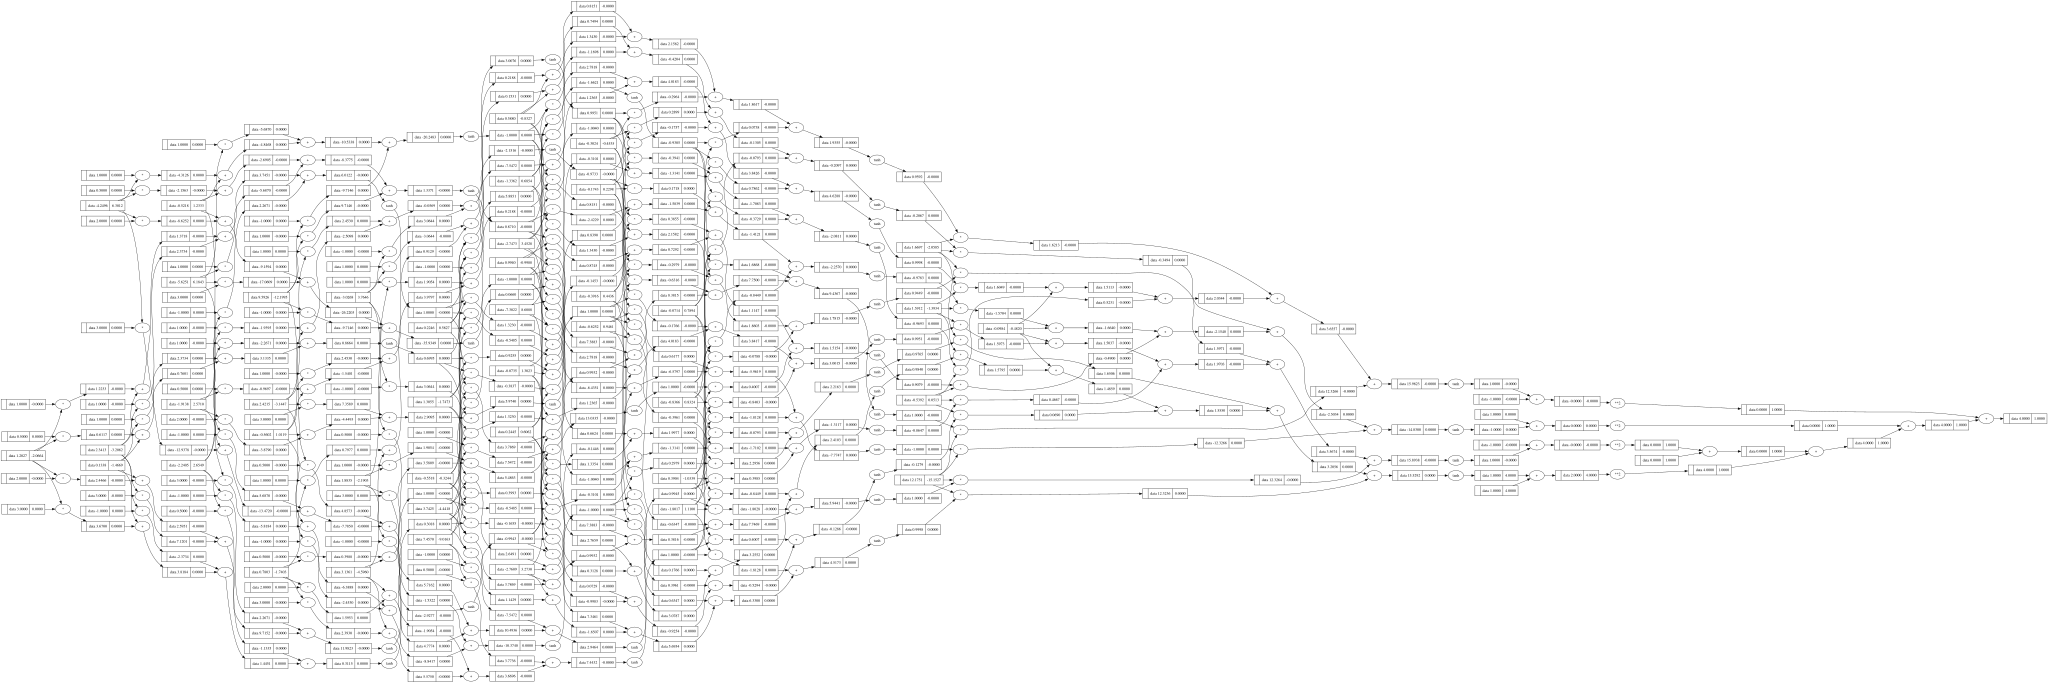

In [154]:
draw_dot(loss)